# Introduction to Probability

Companion notebook for [Introduction to Probability](../../notes/probability/introduction_to_probability.md).

We enumerate sample spaces, compute probabilities of events by counting equally likely outcomes, compare with simulation, and compute expected values.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import product
from fractions import Fraction

rng = np.random.default_rng(42)
plt.rcParams["figure.figsize"] = (7, 3.5)

## 1. Sample space and events by enumeration

Two fair dice give 36 equally likely ordered pairs. Events are subsets of this sample space and, for equally likely outcomes, $P(E)=|E|/|S|$.

In [2]:
S = list(product(range(1, 7), repeat=2))
def prob(event):
    return Fraction(sum(1 for s in S if event(s)), len(S))

print("|S| =", len(S))
print("P(sum = 8)         =", prob(lambda s: sum(s) == 8))
print("P(sum >= 10)       =", prob(lambda s: sum(s) >= 10))
print("P(doubles)         =", prob(lambda s: s[0] == s[1]))
print("P(at least one 6)  =", prob(lambda s: 6 in s))

|S| = 36
P(sum = 8)         = 5/36
P(sum >= 10)       = 1/6
P(doubles)         = 1/6
P(at least one 6)  = 11/36


## 2. The distribution of the sum is not uniform

The 11 possible sums are not equally likely: sum $k$ occurs in $6-|k-7|$ of the 36 pairs.

{2: 1, 3: 2, 4: 3, 5: 4, 6: 5, 7: 6, 8: 5, 9: 4, 10: 3, 11: 2, 12: 1}


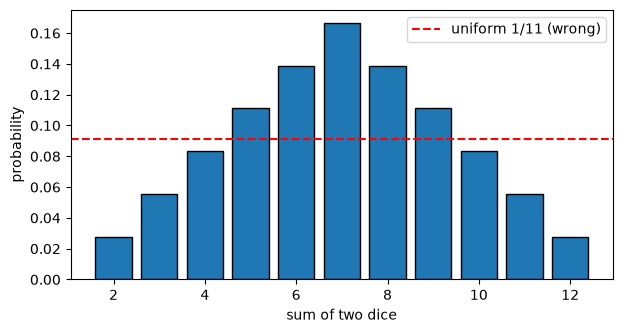

In [3]:
sums = np.arange(2, 13)
pmf = np.array([float(prob(lambda s, k=k: sum(s) == k)) for k in sums])
print(dict(zip(sums.tolist(), np.round(pmf * 36).astype(int).tolist())))

plt.bar(sums, pmf, edgecolor="black")
plt.axhline(1 / 11, color="red", linestyle="--", label="uniform 1/11 (wrong)")
plt.xlabel("sum of two dice"); plt.ylabel("probability"); plt.legend()
plt.show()

## 3. Expected value

$E(X)=\sum_s P(s)X(s)$. For the sum of two dice this is 7. For the larger of the two numbers it is $161/36\approx4.472$.

In [4]:
E_sum = sum(Fraction(sum(s), 36) for s in S)
E_max = sum(Fraction(max(s), 36) for s in S)
print("E(sum) =", E_sum, "=", float(E_sum))
print("E(max) =", E_max, "=", round(float(E_max), 4))

E(sum) = 7 = 7.0
E(max) = 161/36 = 4.4722


## 4. Frequentist check by simulation

The relative frequency of an event in many repeated experiments approaches its probability. We plot the running proportion of rolls with sum $\ge 10$, whose true value is $1/6$.

final estimate: 0.1674  exact: 0.1667


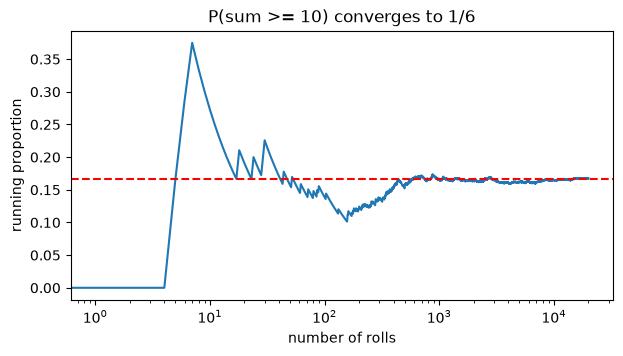

In [5]:
n = 20000
rolls = rng.integers(1, 7, size=(n, 2)).sum(axis=1)
running = np.cumsum(rolls >= 10) / np.arange(1, n + 1)
print("final estimate:", round(running[-1], 4), " exact:", round(1 / 6, 4))

plt.plot(running)
plt.axhline(1 / 6, color="red", linestyle="--")
plt.xscale("log"); plt.xlabel("number of rolls"); plt.ylabel("running proportion")
plt.title("P(sum >= 10) converges to 1/6")
plt.show()

## 5. Balls in cells: distinguishable versus indistinguishable

Three distinguishable balls in three cells give 27 equally likely placements. The event A = "some cell holds at least two balls" and B = "cell 1 is not empty" have $P(A)=21/27$, $P(B)=19/27$, and $P(A\cap B)=13/27$, which the code confirms (this also corrects the intersection count in the note's worked example).

In [6]:
placements = list(product(range(3), repeat=3))   # cell index of ball a, b, c
A = lambda p: len(set(p)) < 3
B = lambda p: 0 in p
n = len(placements)
count = lambda f: sum(1 for p in placements if f(p))
print("n =", n)
print("P(A) =", Fraction(count(A), n))
print("P(B) =", Fraction(count(B), n))
print("P(A and B) =", Fraction(count(lambda p: A(p) and B(p)), n))
print("P(A or B)  =", Fraction(count(lambda p: A(p) or B(p)), n))

n = 27
P(A) = 7/9
P(B) = 19/27
P(A and B) = 13/27
P(A or B)  = 1
